## Assignment 08: Practical Audio Communication Experience


<div class="alert alert-light">

  **Name:** Suleman Ali Khan
  
  **Matriculation Number:** 21-715-917
  
</div>



The submission deadline is <span style="background-color:rgba(0, 150, 255, 0.5); padding:2px 4px; border-radius:3px;">Monday, 2026-Nov-16 (23:59)</span>.
Students <span style="background-color:rgba(255, 123, 0, 0.5); padding:2px 4px; border-radius:3px;">must work alone</span> and provide their own results. 

Fill in your responses below in the marked blocks. The expected length of each answer is provided in each block.

- (S) Short, 1–2 sentences (~20–40 words). *A quick factual or definition-style answer.*
- (M) Medium, 3–8 sentences (~60–120 words). *Brief explanation with reasoning or an example.*
- (L) Long, multi-paragraph (150–300 words). *Detailed discussion, include reasoning, examples, and context.*
- (V) Visualizations and graphs. *Include plots or figures that illustrate your results.*
- (E) Statistical evaluation and information. *Provide numeric context such as mean, variance, random seed used, confidence intervals, etc.*

Save this notebook and upload the modified file to Moodle.

The motivation for this assignment is to explore the fundamentals of acoustic communication by using audible sound as a carrier for data transmission. This involves analyzing how digital data can be modulated into sound using phase, amplitude, frequency encoding and how it affects playback quality and robustness. We then transmit a hidden message over the air in real-world conditions, starting with a mystery clip only you received, and finally build a small acoustic modem ourselves and compare it with what the channel could carry in theory.

**Before you start**

- **Notebooks:** [`Audio_Analysis.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Analysis.ipynb), [`Audio_Encoding.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Encoding.ipynb), [`Audio_Transmission.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Transmission.ipynb) and [`Audio_Modem.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Modem.ipynb). Keep the `Audio` folder next to them.
- **Setup:** `Audio_Transmission.ipynb` needs Docker. Run its setup cell (section 1.1) a day before you start measuring: the first run compiles the watermark engine, needs internet and takes a few minutes.
- **Hardware:** a laptop (speaker) and your phone (microphone, any recorder app; iPhone Voice Memos `.m4a` works directly). Turn off noise suppression or "enhanced" recording in the app if it has one. Something to measure distance with, for example a tape measure or a ruler.
- **Mystery clip:** on Moodle, the page *A08 Mystery Clip* plays the clip you were assigned at random, one of ten, with its variant number and the length of the hidden codeword. You can play it there, but not download it: you have to record it. Nothing is entered on Moodle; the codeword goes into this notebook.
- **Matriculation number:** your message in Step 4 and your modem's tones in Step 5 depend on it.
- **What you hand in:** this notebook and `measurements.csv` (Step 4, question 6). Your audio recordings stay on your computer: do not upload them. The codeword, tables and plots in your answers are the evidence.

---

## Questions



### Step 1: Theory (1 point)

1) Read the lecture slides on Audio Communication and the [background materials](https://gitlab.ethz.ch/wireless/BackgroundReading/-/tree/main/Audiocom):
   * H. Malvar, *A Modulated Complex Lapped Transform and its Applications to Audio Processing*, IEEE 1999  
   * R. Frigg, T. R. Gross and S. Mangold, *Multi-Channel Acoustic Data Transmission to Ad-Hoc Mobile Phone Arrays*, ACM 2013

2) Does acoustic communication rely on electromagnetic waves?

<div class="alert alert-info">

(S) Answer: No. Acoustic communication carries information in mechanical pressure waves traveling through a medium such as air; electromagnetic waves are not the signal carrier.

3) Estimate how fast acoustic waves travel through air.

<div class="alert alert-info">

(S) Answer: At room temperature, sound travels through air at about 343 m/s (roughly 340 m/s); the speed varies with temperature.



4) What is the typical frequency bandwidth of smartphone audio recording?  

<div class="alert alert-info">

(S) Answer: Many smartphones record at 44.1 or 48 kHz sampling rates, corresponding to theoretical upper limits of 22.05 or 24 kHz. The microphone’s actual frequency response can be narrower.



5) What range of frequencies can humans hear (in Hz)?  

<div class="alert alert-info">

(S) Answer: A commonly given range is about 20 Hz to 20,000 Hz (20 kHz), though the upper limit varies and often decreases with age.



6) Compute the wavelength of sound in air at 100 Hz, 1 kHz and 15 kHz. What is the highest frequency a `.wav` file recorded at 16 kHz can contain? Why would moving the phone by a few centimetres ruin a link that encodes bits in the *phase* of a 1 kHz tone?

<div class="alert alert-info">

**(S, E) Answer:** Using the speed of sound, $c \approx 343\,\text{m/s}$, and the wavelength formula $\lambda = c/f$:

- At $100\,\text{Hz}$: $\lambda \approx 3.43\,\text{m}$
- At $1\,\text{kHz}$: $\lambda \approx 0.343\,\text{m}$
- At $15\,\text{kHz}$: $\lambda \approx 0.0229\,\text{m}$ ($2.29\,\text{cm}$)

A WAV file sampled at $16\,\text{kHz}$ can represent frequencies up to $8\,\text{kHz}$ in theory, by the Nyquist limit. At $1\,\text{kHz}$, moving the phone by $1\,\text{cm}$ changes the path-related phase by approximately
$\Delta\phi = 360^\circ \times \frac{0.01}{0.343} \approx 10.5^\circ$.
Moving it a few centimetres can therefore cause a substantial phase shift and disrupt phase-encoded bits.


7) A receiver usually does not know when the sender started, or when you pressed *record*. How can it still find where a message begins?

<div class="alert alert-info">

(S) Answer: The sender can start with a known synchronization sequence (a preamble). The receiver searches for that pattern—often using correlation—to detect the start and align its timing before decoding the message.



### Step 2: Audio Analysis (2 points)

1) Open [`Audio_Analysis.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Analysis.ipynb) and set `FILE_A="Audio/CrabRave.wav"` and `FILE_B="Audio/DarudeSandstorm.wav"`. Visualize 5s of both files in time domain. How does the amplitude vary? Are there silent intervals? 

<div class="alert alert-info">

(V, M) Answer: 

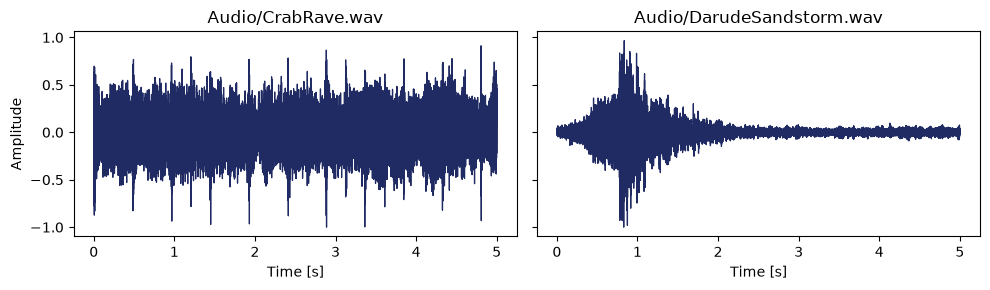

The 5-second waveform plots show different amplitude patterns. *CrabRave.wav* stays at a fairly high, fluctuating amplitude throughout the segment, with frequent peaks and dips but no obvious silent interval. *DarudeSandstorm.wav* starts quietly, swells to a strong burst at around 0.8–1 second, and then decays. After about 2 seconds its amplitude is much lower, but the waveform still shows a quiet signal rather than a clearly silent interval.


2) Visualize both files in frequency domain. What does the spectrum describe? Where is the frequency highest and lowest?

<div class="alert alert-info">

(V, M) Answer:

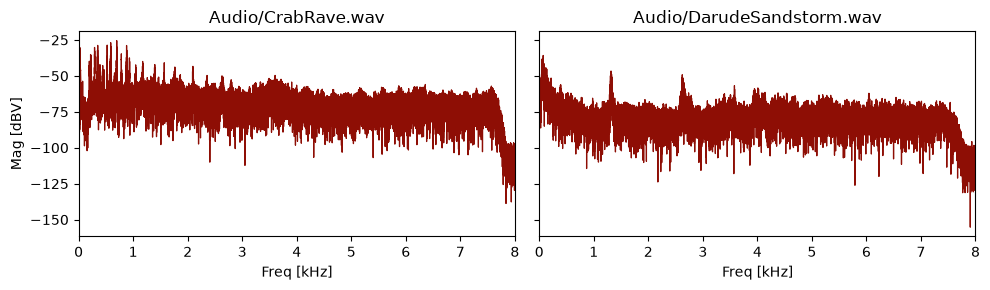

A frequency spectrum shows the signal’s magnitude (or energy) at each frequency, indicating which frequency components are strongest. In these plots, both files contain components across most of the displayed range, from near $0$ to $8\,\text{kHz}$. The strongest magnitudes are at low frequencies—roughly below $1\,\text{kHz}$, especially for *DarudeSandstorm.wav*. The weakest magnitudes are near the upper end, around $8\,\text{kHz}$, where both spectra drop sharply. This is the highest frequency shown; it is also the Nyquist limit for a $16\,\text{kHz}$ sampling rate.


3) Visualize 5s of both files as a spectrogram. What does a spectrogram show? Can you detect a pattern over time? What part of the audio is creating this pattern? Count the beats in your 5 s window and compare with the estimate in section 1.5 of the notebook: how many beats per minute does each song have?

<div class="alert alert-info">

(V, M) Answer: 

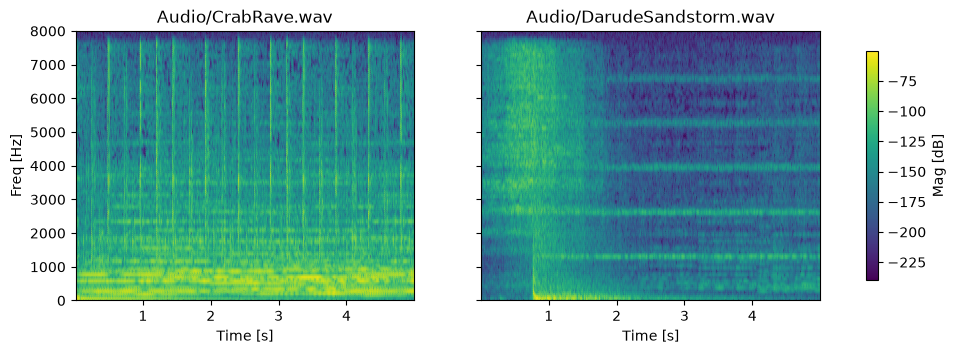

A spectrogram shows how a signal’s frequency content and magnitude change over time. Repeated vertical changes are visible, especially in *CrabRave.wav*; these are mainly caused by rhythmic percussive sounds, such as drum or kick hits, which create short bursts of energy across many frequencies. The pattern is less distinct in *DarudeSandstorm.wav*.

Counting the beats in the 5-second window gives approximately **10 beats** for *CrabRave* and **9 beats** for *DarudeSandstorm*. The notebook’s 30-second tempo estimator gives about **125 BPM** and **136 BPM**, respectively; these correspond to about **10.4** and **11.3 beats per 5 seconds**, consistent with the visual counts.


4) Why should you avoid encoding very low or very high frequencies in audio?

<div class="alert alert-info">

(S) Answer: Very low and very high frequencies are reproduced inconsistently by speakers and microphones, and may be attenuated or distorted by the environment. High frequencies also suffer greater air absorption and are more easily blocked, while very low frequencies can be masked by ambient noise; using a mid-range band improves reliability.


5) Which of the two files is more suited to carry data? Assume an encoding that modifies the existing data. Why?

<div class="alert alert-info">

(M) Answer: *CrabRave.wav* is likely more suitable for carrying data by modifying the existing audio. Its amplitude remains relatively high and its sound is dense throughout the 5-second segment, so changes can be masked by the music and are less likely to be noticeable. *DarudeSandstorm.wav* becomes much quieter after its strong opening burst, making modifications in those sections more audible. The choice depends on the encoding method, but a consistently energetic signal generally provides better masking.


6) Your channel. Record the mystery clip from Moodle with your phone at about 30 cm (you need this recording for Step 4 anyway), and in the same spot 5 s of room noise with nothing playing. In section 2 of `Audio_Analysis.ipynb`, compare the spectrum of your recording with `CrabRave.wav` and provide the plot and the band table. What did the speaker, the room and the microphone change? Is your room noise close to white noise? What is the SNR of your recording?

<div class="alert alert-info">

(V, E, M) Answer: 

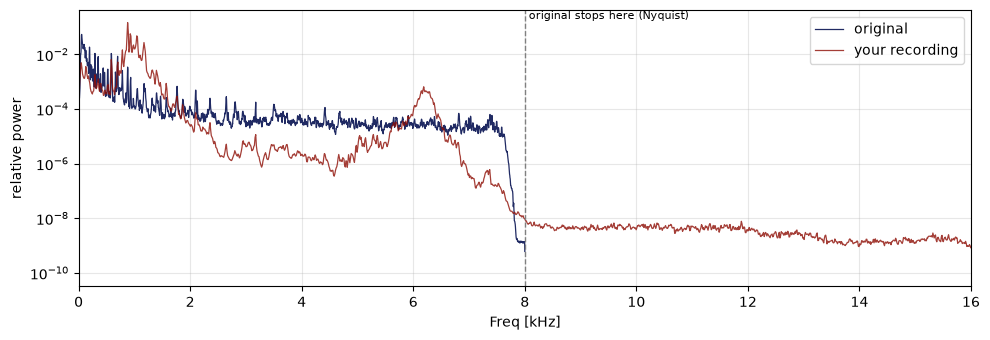

The speaker, room, and phone microphone changed the recording’s frequency balance. Compared with the original, the recording has less power at 0–250 Hz (-12.9 dB) and 2–6 kHz (-12.1 dB), more power at 250 Hz–2 kHz (+5.7 dB), and a similar level at 6–8 kHz (+0.3 dB). The -55.8 dB of measured energy above 8 kHz is noise or distortion; the original has no content above that limit.

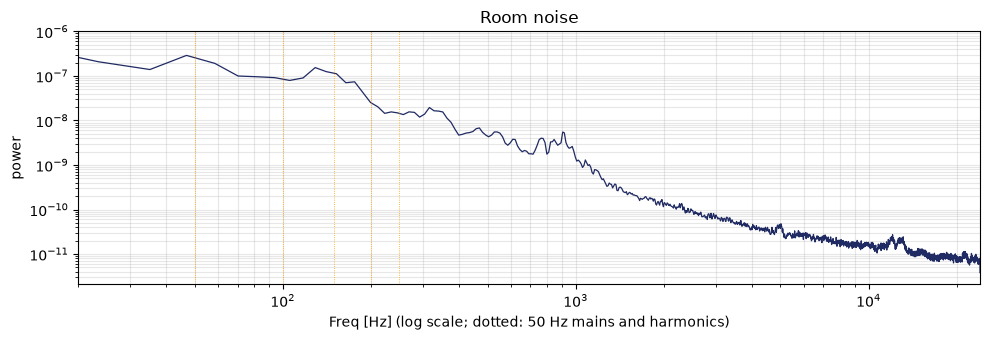

The room noise is not close to white noise: its 100–500 Hz band has 30.6 dB more power than its 4–8 kHz band, whereas white noise would be roughly flat. The recording’s SNR over 100 Hz–8 kHz is **11.2 dB**, meaning the estimated signal power is about 13 times the noise power.


### Step 3: Data Encoding in Audio (2 points)

1) Open [`Audio_Encoding.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Encoding.ipynb). Encode a message into `CrabRave.wav` using LSB Encoding. Analyze the new file in time, frequency and spectrogram domain and provide the new graphs. How does this modulation affect the signal?

<div class="alert alert-info">

(V, S) Answer: 

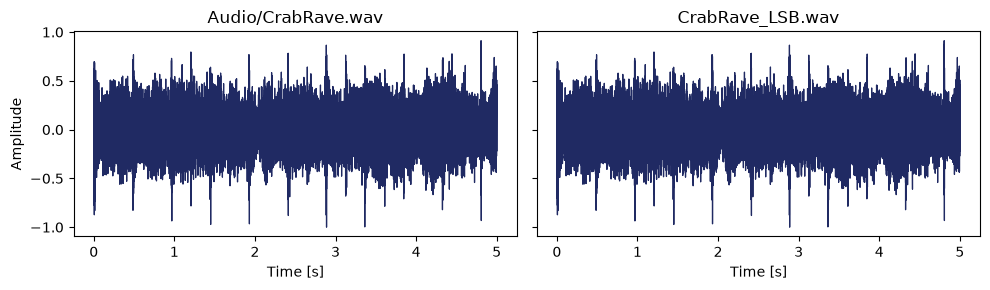

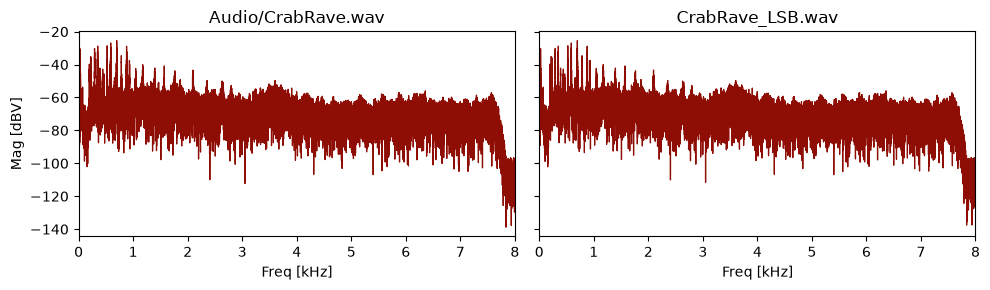

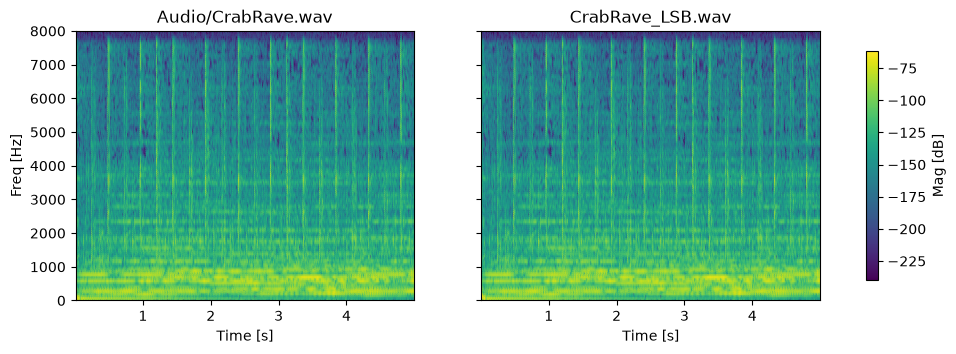

The LSB-encoded signal looks almost identical to the original in the time plot, frequency spectrum, and spectrogram. LSB encoding changes only the least significant bits of audio samples, causing very small amplitude changes that are generally inaudible and do not noticeably alter the signal’s overall frequency content.


2) Encode a message into `CrabRave.wav` using Phase Modulation. Analyze the new file in time, frequency and spectrogram domain and provide the new graphs. How does this modulation affect the signal?

<div class="alert alert-info">

(V, S) Answer: 

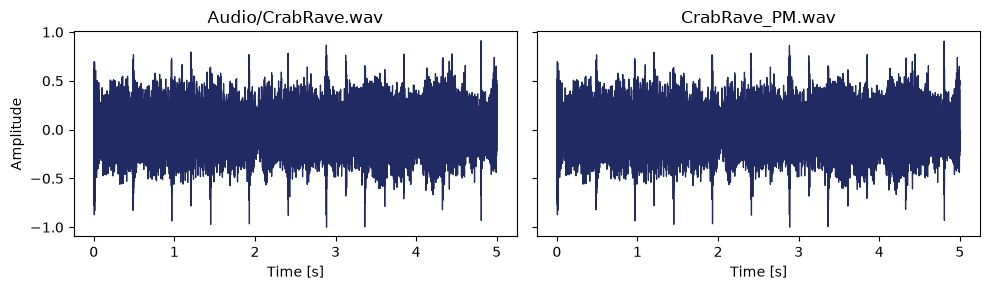

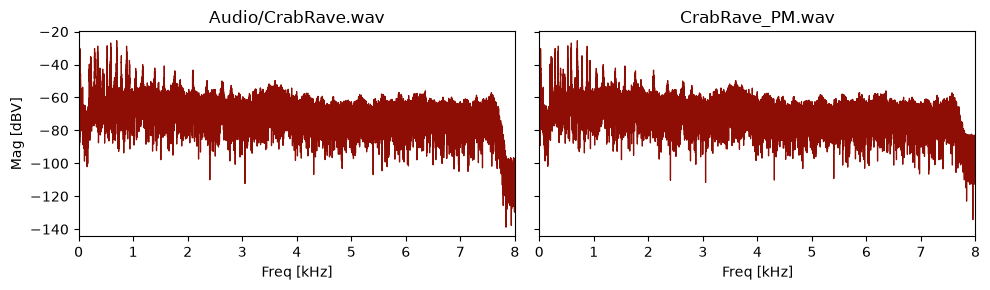

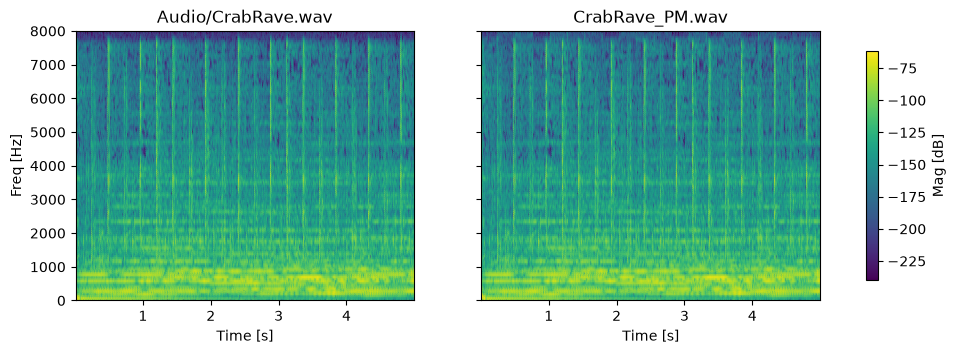

The phase-modulated file appears very similar to the original in all three plots: the overall waveform amplitude, frequency spectrum, and spectrogram show no obvious large-scale changes. Phase modulation encodes data by slightly changing the phase of the audio signal while largely preserving its amplitude and frequency content, so the changes are subtle in these visualizations.


3) Encode a message into `CrabRave.wav` using Spread Spectrum Noise. Analyze the new file in time, frequency and spectrogram domain and provide the new graphs. How does this modulation affect the signal?

<div class="alert alert-info">

(V, S) Answer: 

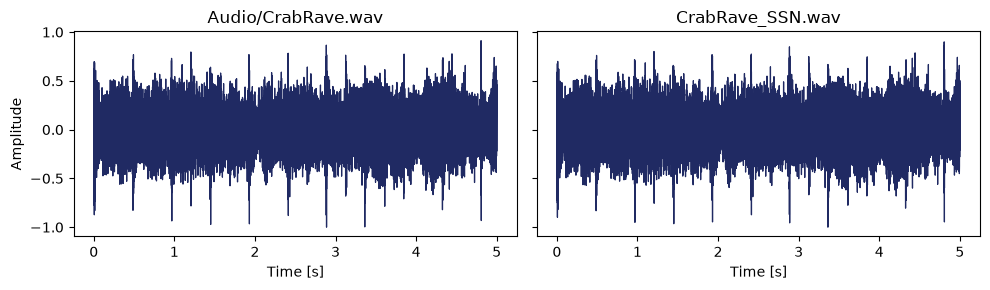

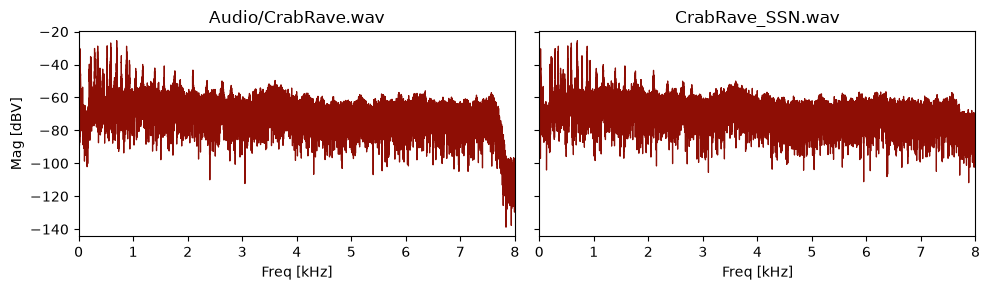

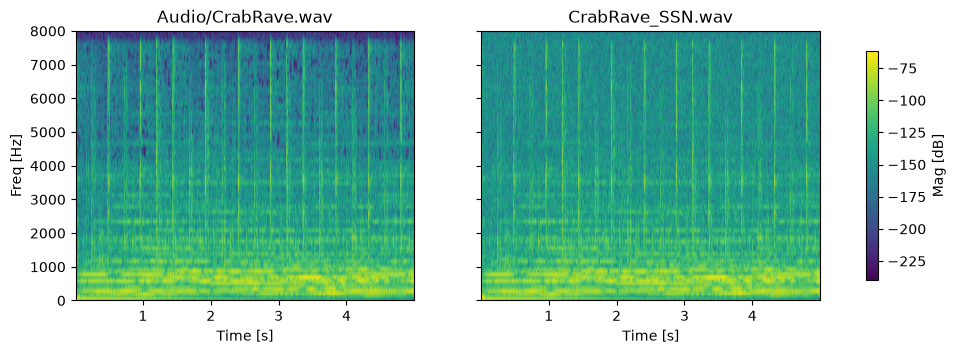

The spread-spectrum noise encoded file has a time waveform and spectrogram that look broadly similar to the original, but its frequency spectrum shows a raised noise-like floor across the band. In the spectrogram, the encoded file is especially greener/yellower near the high-frequency end, around 8 kHz, indicating higher magnitude there than in the original. This reflects the added spread-spectrum noise, which raises the background energy across many frequencies.



4) Play the output sound files (`CrabRave_LSB.wav`, `CrabRave_PM.wav`, `CrabRave_SSN.wav`). Analyze the embedding techniques in terms of their perceptual effect on audio quality. Do not rely on just listening: run the blind listening test in section 3.4 of the notebook once for each method and report your three scores.

<div class="alert alert-info">

(S, E) Answer: 

Blind Listening Results:

- LSB: 5/10 correct
- PM: 4/10 correct
- SSN: 10/10 correct

LSB and PM were difficult to distinguish from the original in this small test (chance is about 5/10), while SSN was consistently distinguishable, suggesting its added noise had the clearest perceptual effect on audio quality.


5) Decode the embedded data. How accurately can you recover the original message for each technique?

<div class="alert alert-info">

(M) Answer: 

LSB clean: BER = 0.0000 (0 errors / 524288)
LSB noisy: BER = 0.5008 (262552 errors / 524288)

PM clean: BER = 0.0000 (0 errors / 15424)
PM noisy: BER = 0.3815 (5885 errors / 15424)

SSN clean: BER = 0.2144 (1124 errors / 5242)
SSN noisy: BER = 0.2133 (1118 errors / 5242)

In a clean channel, LSB and PM recover the message perfectly, with BERs of 0.0000. Under noise, LSB’s BER rises to 0.5008 (about 49.92% of bits correct), making recovery essentially no better than guessing; PM performs better but still has a high BER of 0.3815 (about 61.85% correct). SSN has a BER of about 0.214 in both clean and noisy conditions, corresponding to roughly 78.6% of bits correct. Thus, SSN is the most robust to the added noise in these results, although its decoding is not error-free even in the clean case.


6) Run the channel attacks in section 3.5 of the notebook: noise from 40 to 0 dB SNR, MP3 compression and echo. Provide the plot and the table. Which technique maintains data integrity best? On a high level, explain why.

<div class="alert alert-info">

(V, M) Answer: 

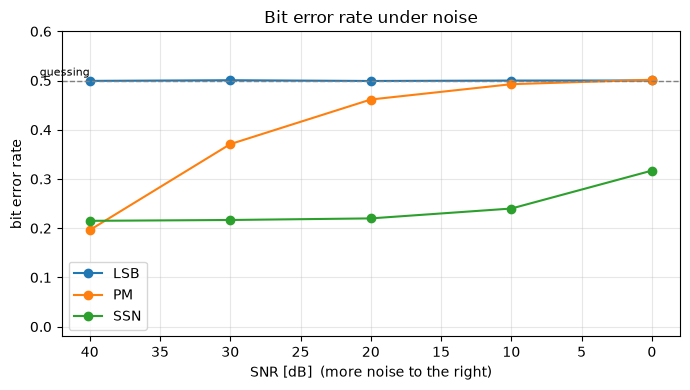

| Method | 40 dB | 30 dB | 20 dB | 10 dB | 0 dB | MP3 128k | Echo |
|---|---:|---:|---:|---:|---:|---:|---:|
| LSB | 0.499 | 0.501 | 0.499 | 0.500 | 0.500 | 0.500 | 0.501 |
| PM | 0.196 | 0.371 | 0.461 | 0.493 | 0.502 | 0.505 | 0.203 |
| SSN | 0.215 | 0.217 | 0.220 | 0.240 | 0.317 | 0.233 | 0.260 |

The plot and BER table show that **SSN is the most robust overall**: its BER remains relatively low across the tested noise levels, MP3 compression, and echo. Phase modulation performs slightly better at 40 dB and under echo, but its BER rises close to 0.5 with stronger noise and MP3 compression. LSB stays near 0.5 for all attacks, meaning its decoding is essentially no better than guessing. SSN spreads the data across the signal, so damage to particular samples or parts of the signal is less likely to destroy all the encoded information; LSB is easily corrupted by small sample changes, while phase can be disrupted by noise and echoes.

7) Determine which method should be used in what scenario and explain why.

<div class="alert alert-info">

(M) Answer: 

Use **LSB** when the audio will remain digital and unmodified, since it can carry many bits and decoded perfectly in the clean test, but even small channel changes make it unreliable. **Phase modulation (PM)** may be suitable when resistance to echo matters, as it performed best in that test, but it struggled with stronger noise and MP3 compression. Use **spread-spectrum noise (SSN)** when robustness to noise or compression is more important than imperceptibility or high data capacity; it had the best overall BER under the tested attacks, though it was not error-free. The best choice therefore depends on whether capacity, audio transparency, or channel robustness is the priority.


### Step 4: Practical Over-The-Air Audio Communication (5 points)

Open [`Audio_Transmission.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Transmission.ipynb) and run its setup cell (section 1.1). The helper file `audio_watermark.py` must be in its `Audio` folder.

1) **The mystery clip.** The Moodle page *A08 Mystery Clip* plays a music clip with a secret codeword hidden in it. Play it on your laptop, record it with your phone at about 30 cm, and decode it with section 1.9 of the notebook. Report your variant number, the codeword and the decoder's confidence in the answer block below, and provide a photo of the setup. The recording itself is not handed in.

<div class="alert alert-info">

(V, S) Answer: 

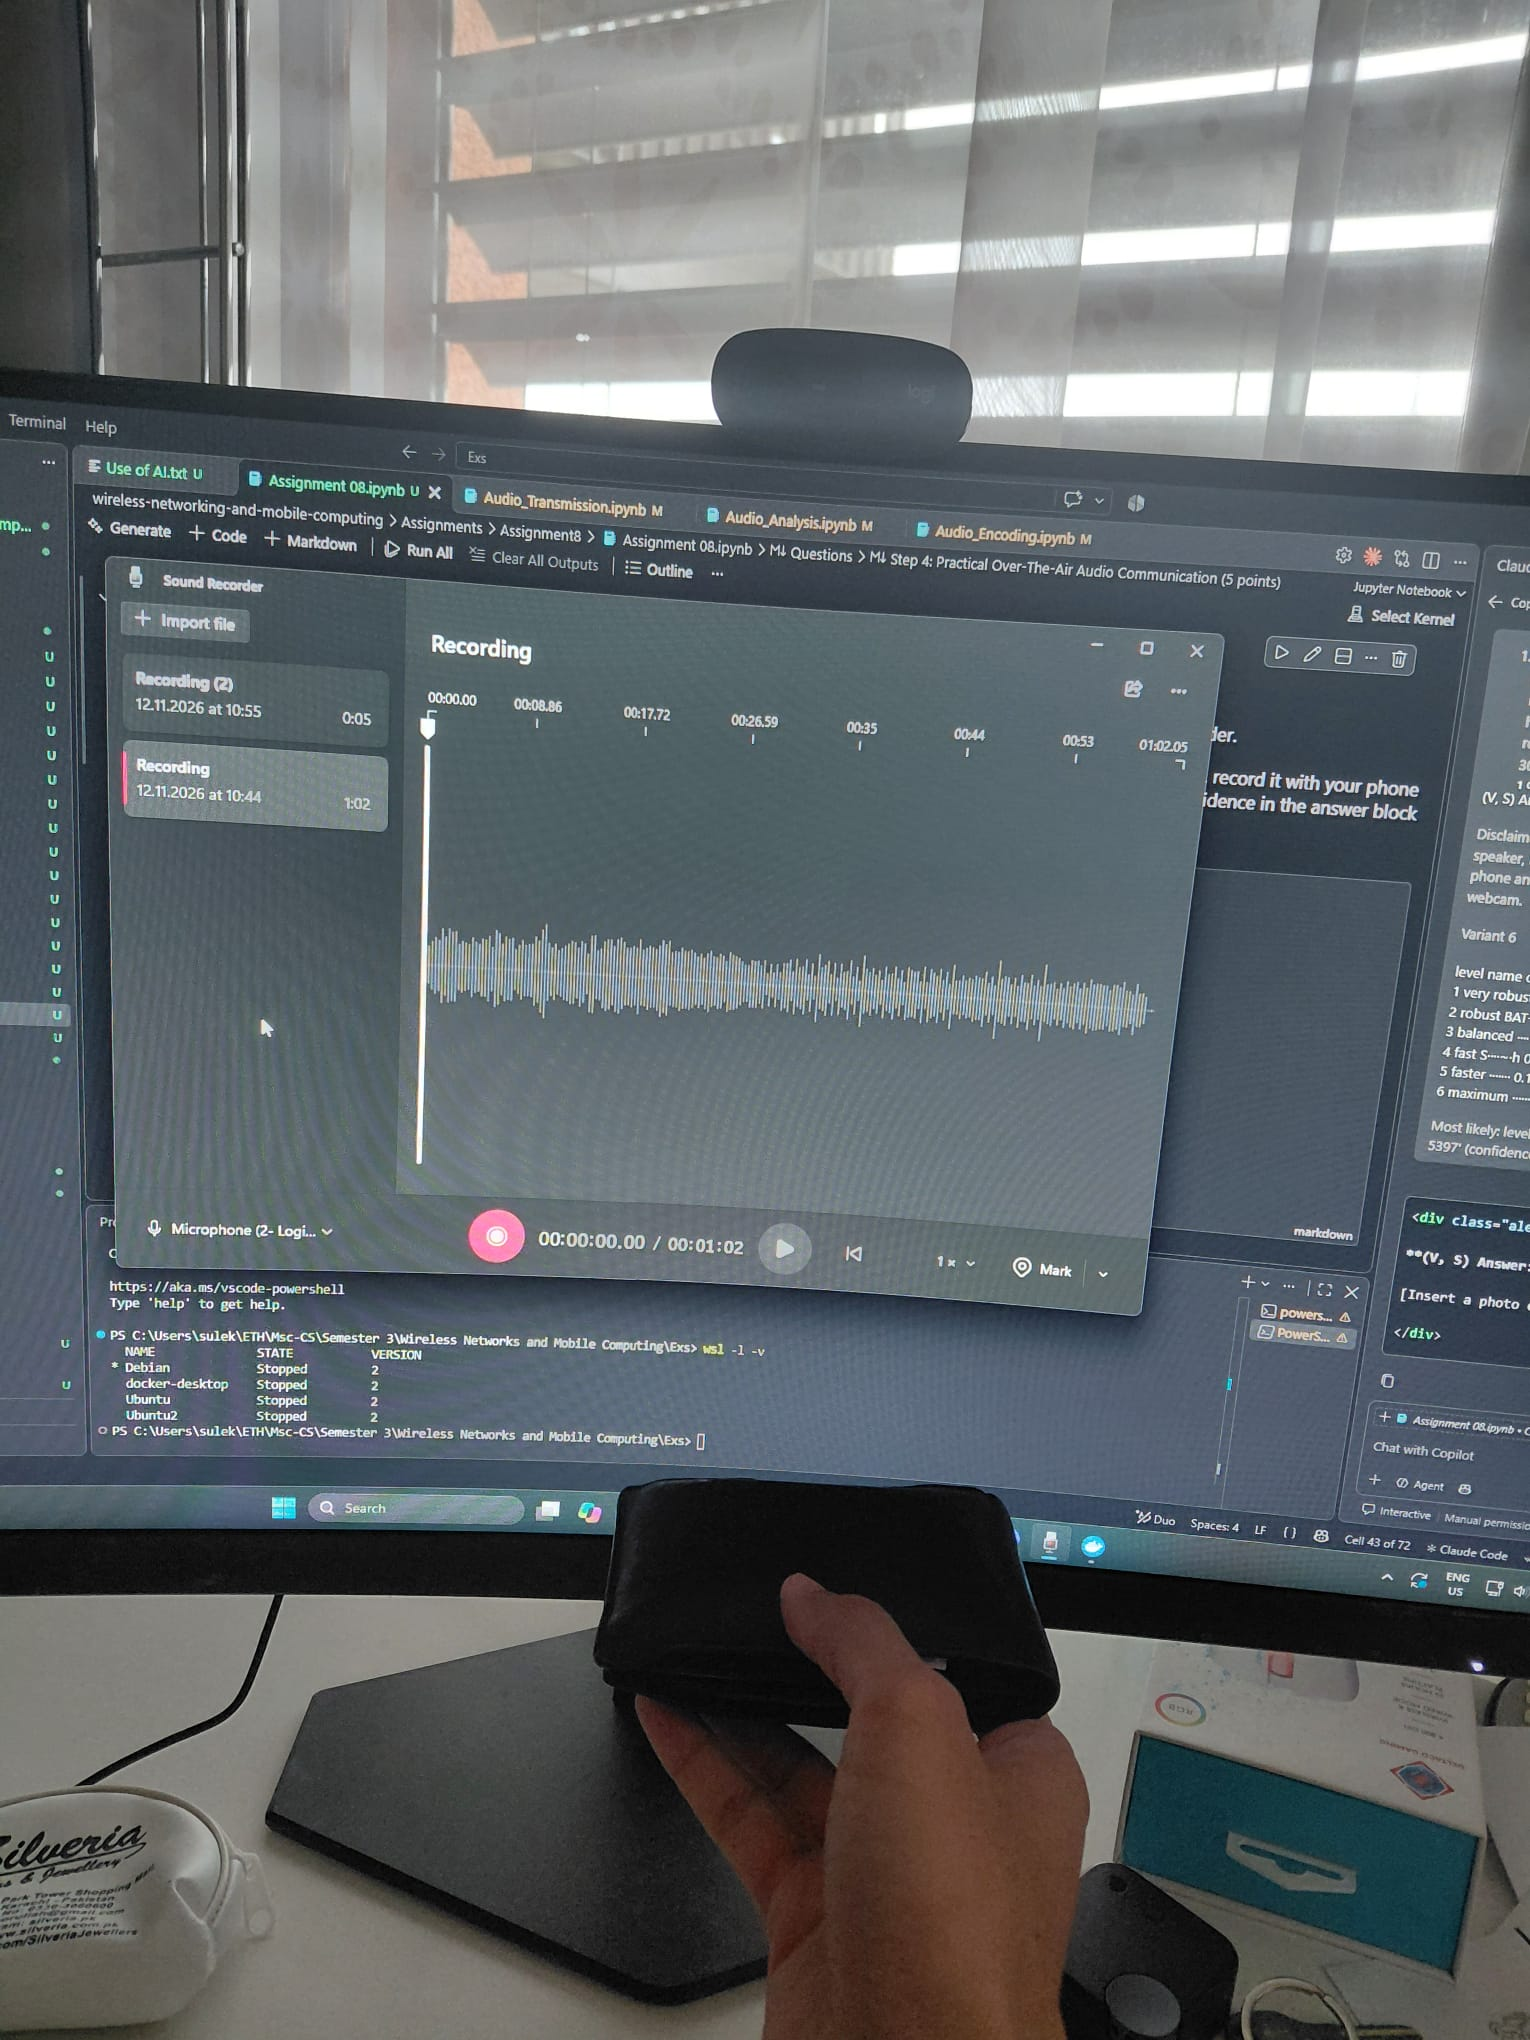

I played the audio on my phone and recorded it with my PC’s webcam because my computer does not have a speaker. Since I used my phone to take the setup photo, the black wallet in the picture marks where the phone was placed during recording. The webcam is mounted above my monitor.

**Variant:** 6

| Level | Name | Decoded result | Confidence |
|---:|---|---|---:|
| 1 | Very robust | ··G·n··· | 0.34 |
| 2 | Robust | BAT-5397 | 1.79 |
| 3 | Balanced | ····^x·} | 0.14 |
| 4 | Fast | S····~·h | 0.22 |
| 5 | Faster | ······· | 0.13 |
| 6 | Maximum | ·······> | 0.15 |

The most likely result is **BAT-5397**, decoded at level 2 (“robust”) with a confidence score of **1.79**.


2) Moodle tells you only the length of the codeword, not the level it was hidden with. Provide the table of all six levels from section 1.9. How do you recognise the right level? Record the clip once more, but start only about halfway through. Does the codeword still decode? What does this tell you about where in the song it is stored?

<div class="alert alert-info">

(E, M) Answer:

The correct level is the one that produces the expected-length codeword and a clearly higher confidence than the other outputs. Here, level 2 decodes to the same valid codeword, **BAT-5397**, in both recordings, and has the highest confidence each time. The confidence decreases from 1.79 to 0.52 when recording from halfway through, but the codeword is still recovered.

| Level | Name | Full-clip result | Confidence | Halfway-start result | Confidence |
|---:|---|---|---:|---|---:|
| 1 | Very robust | ··G·n··· | 0.34 | ·%·1ZN·· | 0.16 |
| 2 | Robust | BAT-5397 | 1.79 | BAT-5397 | 0.52 |
| 3 | Balanced | ····^x·} | 0.14 | T···^x·} | 0.13 |
| 4 | Fast | S····~·h | 0.22 | ·%···v·· | 0.13 |
| 5 | Faster | ······· | 0.13 | ····)>·· | 0.23 |
| 6 | Maximum | ·······> | 0.15 | ~····Y·· | 0.13 |

Decoding the same codeword from a recording that starts halfway through suggests that the data is not confined to the beginning of the song. It may be repeated or distributed through the audio, allowing the decoder to recover it from a later portion.


3) Move the phone further away (for example 50 cm, 1 m and 2 m) and decode the mystery clip at each distance. At which distance does the codeword stop decoding? Report the decoded text and the confidence at each distance.

<div class="alert alert-info">

(E, S) Answer: 

The correct codeword (**BAT-5397**) did not decode at any of the tested distances beyond the initial recording. It had already stopped decoding at the first increased distance tested, **50 cm**.

| Distance | Most likely decoder output | Confidence |
|---|---|---:|
| 50 cm | `········` (level 2) | 0.24 |
| 1 m | `"·C···:A` (level 3) | 0.32 |
| 2 m | `T···~···` (level 5) | 0.11 |

These outputs do not match the expected codeword, and their low confidence indicates that none is a reliable decode.


4) Now hide your own message. In section 1.2 of the notebook, set the message to your matriculation number. Embed it into `CrabRave.wav` with `LEVEL = 2` and listen to the encoded version `CrabRave_Encoded.wav`. Can you hear a difference?

<div class="alert alert-info">

(S) Answer: No, I could not hear a noticeable difference between the original and the encoded audio.


5) Create your own testbed: set up both a speaker (laptop, phone, etc.) and a microphone (laptop, phone, etc.) where you can vary the distance from 10cm to 100cm. You will play `CrabRave_Encoded.wav`, save the recording as `CrabRave_Recorded.wav` and decode it. Provide an image of your setup and name the hardware you used. The measured distance must be visible in the image (for example a ruler or tape measure in frame).

<div class="alert alert-info">

(V, S) Answer: 

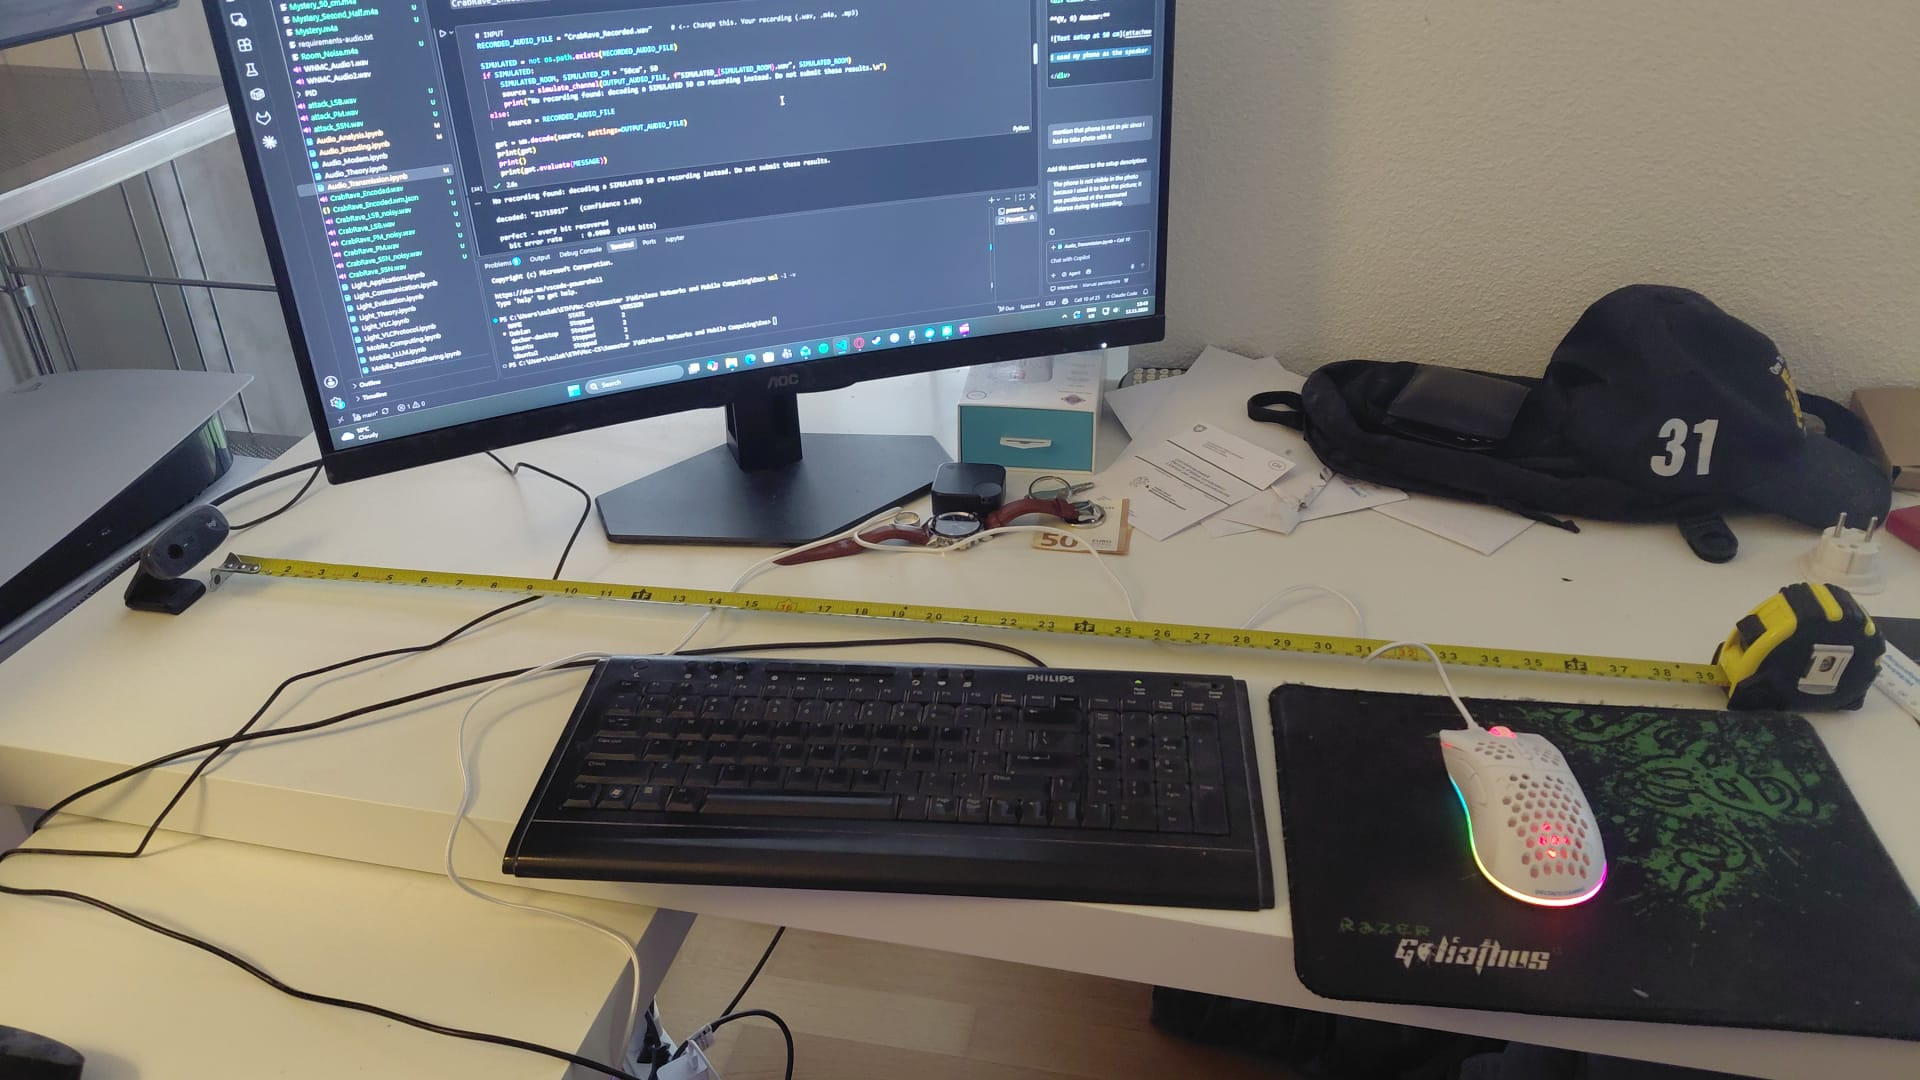

I used a Logitech webcam as the microphone and my phone as the speaker. I used a measuring tape to measure the distance between them. The phone is not visible in the photo because I used it to take the picture. Also dont mind the mess 🤣



6) Vary the distance between speaker and microphone: 10cm, 50cm and 100cm. Use `LEVEL = 2` and `LEVEL = 4` for each distance, each with the longest message that fits (`show_levels()` shows it). Generate one plot for each level where you show both the BER and character accuracy for each given distance. Provide and interpret the numbers in each plot in a textual form as well. Submit your raw measurements as a `.csv` table (the notebook writes it as `measurements.csv`).

<div class="alert alert-info">

(V, M) Answer: 

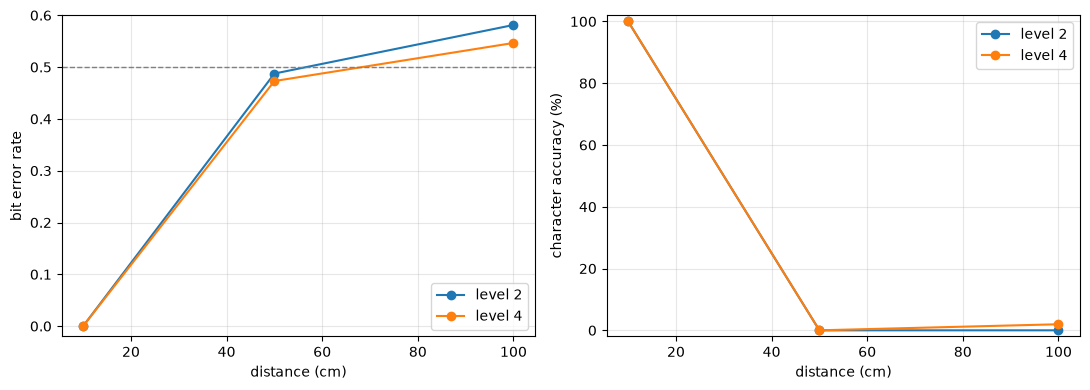

Both levels decoded perfectly at 10 cm, with a BER of 0 and 100% character accuracy. At 50 cm, the BER rose to about 0.49 for level 2 and 0.48 for level 4, while character accuracy fell to 0%. At 100 cm, BER was about 0.58 for level 2 and 0.55 for level 4; character accuracy remained near 0% (about 2% for level 4). Overall, increasing the distance sharply reduced decoding performance. Level 4 was only slightly better at longer distances, and neither level reliably recovered the message beyond 10 cm.


7) What is the main reason for bit errors? What is the smallest BER you can achieve and what settings did you use?



<div class="alert alert-info">

(M) Answer: 


The main cause of bit errors is the acoustic channel: as the speaker and microphone move farther apart, the received signal becomes weaker relative to room noise, and reflections can distort it. In my tests, the smallest BER was **0** at **10 cm**, for both **level 2 and level 4** using the longest message that fit. At 50 cm and 100 cm, the BER increased substantially and character accuracy fell to almost zero. Thus, the best tested result was at the shortest distance; the zero BER applies to these measurements, not necessarily every recording.



8) What is the maximum distance between devices at which a message can still be transferred correctly (or has the highest character accuracy)? What settings did you use?

<div class="alert alert-info">

(S) Answer: 

The maximum tested distance with correct decoding (100% character accuracy) was **10 cm**, using either **level 2 or level 4** with the longest message that fit. At 50 cm and 100 cm, character accuracy was 0% or nearly 0%.


9) Repeat one of the measurements and move the speaker or microphone during (a section of) the recording. How does movement during recording affect the BER? Provide the new results.

<div class="alert alert-info">

(M) Answer: 

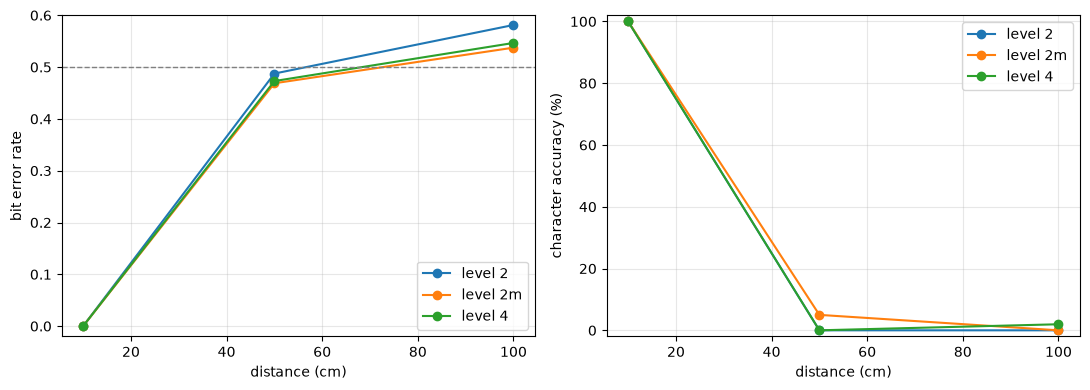

I moved the phone 50 cm farther away after 30 seconds during the 10 cm and 50 cm trials, and 50 cm closer during the 100 cm trial. At 10 cm, decoding remained perfect (BER 0, character accuracy 100%). At 50 cm, the movement trial had a BER of about 0.47 and 5% character accuracy; at 100 cm, it had a BER of about 0.54 and roughly 0–2% character accuracy. Thus, movement did not restore reliable decoding at the longer distances. A changing distance alters the received signal during transmission, but in these results the distance itself appears to be the dominant limitation.


### Step 5: Build Your Own Acoustic Modem (2 points)

The watermark hides data inaudibly, but slowly. A modem does the opposite: it turns data into clearly audible tones, and in exchange it is much faster. Open [`Audio_Modem.ipynb`](../../notebooks/04%20Mobile%20Computing/Audio_Modem.ipynb) and set your matriculation number: your tones and symbol length depend on it.

1) In section 1.3, write the detector: `tone_energies` and `demodulate`. Paste your two functions and the output of the self-test.

<div class="alert alert-info">

(S) Answer: 

The detector measures the magnitude of each expected tone’s DFT coefficient. The demodulator selects the strongest tone for each symbol and converts its index back to two bits.

```python
def tone_energies(segment, rate, tones):
    """Return one DFT magnitude per tone for this symbol."""
    segment = np.asarray(segment, dtype=float).ravel()
    tones = np.asarray(tones, dtype=float).ravel()
    samples = np.arange(segment.size)
    phases = 2 * np.pi * np.outer(tones, samples) / rate
    return np.abs(np.exp(-1j * phases) @ segment)


def demodulate(energies):
    """Convert each strongest tone index into two bits, MSB first."""
    symbols = np.argmax(np.asarray(energies), axis=1)
    bits = np.column_stack((symbols // 2, symbols % 2))
    return bits.astype(np.uint8).ravel()
```


PASS  sent 'SELFTEST-123'  got 'SELFTEST-123'  (tones 1000, 1200, 1400, 1600 Hz, symbol 40 ms -> 25.0 symbols/s, 50.0 bit/s, 48000 Hz)

PASS  sent 'Hello WNMC!'  got 'Hello WNMC!'  (tones 1500, 1700, 1900, 2100 Hz, symbol 30 ms -> 33.3 symbols/s, 66.7 bit/s, 44100 Hz, noise)

PASS  sent '21-987-654'  got '21-987-654'  (tones 800, 1000, 1200, 1400 Hz, symbol 60 ms -> 16.7 symbols/s, 33.3 bit/s, 48000 Hz, noise)

All tests passed.

2) In section 1.4, play `Modem_TX.wav` on your laptop and record it with your phone at about 30 cm. Provide the spectrogram of your recording and the decoded text. Which parts of the frame can you see?

<div class="alert alert-info">

(V, S) Answer: 

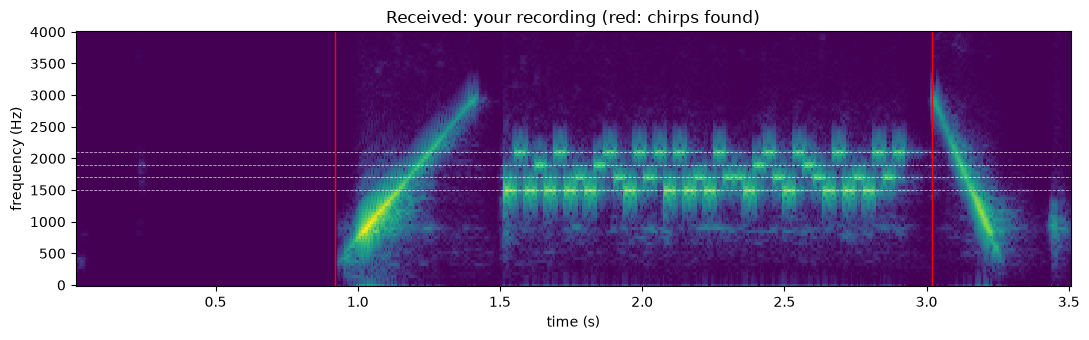

up-chirp at 0.920 s (match 0.46), down-chirp at 3.021 s (match 0.55), payload 1.520 .. 2.921 s
40 symbols -> 80 bits -> '21-715-917'
sent '21-715-917', received '21-715-917': 10/10 characters correct

The spectrogram shows the transmitted text **`21-715-917`** was decoded. The frame’s rising up-chirp appears first, followed by the payload as short horizontal tone segments; the falling down-chirp marks the end. The red vertical lines indicate the chirps detected by the receiver.


3) In section 1.5, shorten the symbol length step by step, at the same distance, until the message no longer decodes. What is the highest bit rate that still worked? What limits it?

<div class="alert alert-info">

(E, S) Answer: 

up-chirp at 1.843 s (match 0.45), down-chirp at 3.243 s (match 0.53), payload 2.443 .. 3.143 s
20 symbols -> 40 bits -> '·····'
sent '21-715-917', received '·····': 0/10 characters correct

The highest rate I confirmed working was at the original **35 ms per symbol**, or about **57.1 bit/s**. At **17.5 ms per symbol** (about **114.3 bit/s**), the message no longer decoded. Shorter symbols leave less time to measure each tone, making tone detection and symbol timing more sensitive to noise and recording-channel distortion.


4) Compare your modem with the watermark of Step 4: audibility, bit rate, robustness and how each one finds the start of the message. Which would you choose for a museum app that receives the room number from a loudspeaker, and which for marking a radio jingle? Why?

<div class="alert alert-info">

(M) Answer: 

The modem sends clearly audible 4-FSK tones, giving it a relatively high bit rate, but its performance can degrade with distance, noise, and echoes. It marks the message boundaries with up- and down-chirps, which the receiver detects to locate and synchronize with the frame. The watermark embeds data into existing audio, so it is designed to be unobtrusive, but carries data more slowly and may be affected by audio processing or channel conditions. For a museum app receiving a room number from a loudspeaker, I would choose the **modem**: the short, explicit transmission is easy for an app to detect and decode. For marking a radio jingle, I would choose the **watermark**, because it can carry a hidden identifier without adding an obvious audible signal.


5) In section 1.6, compute the Shannon capacity $C = B\log_2(1+\mathrm{SNR})$ of your acoustic channel, with the SNR you measured in Step 2 (question 6) and the band your modem uses. Compare it with the bit rates of your modem and of the watermark. Why are both so far below $C$?

<div class="alert alert-info">

(M, E) Answer: 

- bandwidth B          : 800 Hz
- Shannon capacity C   :   3060.8 bit/s  at 11.2 dB SNR
- your FSK modem       :     57.1 bit/s  (1.9 % of C)
- watermark, level 2   :      2.6 bit/s  (0.08 % of C, but in the whole audio band and inaudible)

These practical rates are much lower than the theoretical capacity because Shannon capacity assumes ideal coding and a channel model, while these systems prioritize simplicity and reliability under real acoustic conditions. The modem uses discrete tones and spends time on synchronization chirps and symbol guards. The watermark prioritizes being inaudible and robust within music, which limits how much data can be embedded.


### Optional Feedback (not graded)

1. Did you read through and understand all the tasks in this assignment and the related notebooks? Are there any shortcomings, missing parts, or sections that should be improved? You can also give your feedback anonymously, through moodle. Please help the teaching team by telling us what part was not understood, and we will work on it in the future.

<div class="alert alert-info">

Optional Feedback, not graded: *(double click to edit)*